# Computing velocities from positions

If you run this notebook on your own computer (recommended), you need:
* julia (https://julialang.org/downloads/#official_binaries_for_manual_download)
* some julia packages:
    * `PythonPlot` (or `PyPlot`, but `PyPlot` is difficult to install on Windows)
    * `DelimitedFiles` for reading CSV files
    * `DSP` for digital signal processing)
    * `NCDatasets` for loading NetCDF files

* **If** you are using your own computer, you can install these packages with the following julia commands:

```julia
using Pkg
Pkg.add(["PythonPlot", "DelimitedFiles", "DSP", "NCDatasets"])
using PythonPlot, DelimitedFiles, DSP, NCDatasets
```

But the packages need to be installed before the lecture.
The steps above are not necessary if you work on the notebook server (https://notebook-gher.uliege.be), **but you need to download your files after each lesson (as they are deleted)**. 

## Exercice

* Compute the drifter velocities from the provided file (drifter number 1).
* Remove the part of the data where the drifter was not deployed or when it was stuck at the coast
* Smooth the data with a second order Butterworth filter (with a cut-off frequency corresponding to a period of 30 minutes) from the `DSP` package (example code is provided below).
* Plot the trajectory and the currents with the coastline and bathymetry (isobath 25 m, 50 m, 75 m, 100 m)
  
Data files:
* Drifter positions: https://dox.ulg.ac.be/index.php/s/A3KkDQYmdNLlabx/download . The data is in the CSV format (comma-separated values) where the columns are the time (in UTC), longitude (degree East) and latitude (degree North).
* Bathymetry: https://dox.ulg.ac.be/index.php/s/9ZwWDbsTgCwgS90/download as a NetCDF file.

You are explicitly encouraged to consult the documentation of these software packages and to use a search engine.

Additional information:
* The module `DelimitedFiles` allows you to read CSV formatted files with the command `readdlm`. The command `?readdlm` provides for more information. Use for example `readdlm(filename,',');` of the columns a separated by a comma.
* You can convert a string `"2024-05-08T06:20:15"` into a `DateTime` structure (from the module `Dates`) by calling `DateTime("2024-05-08T06:20:15")`
* You can compute the number of seconds between e.g. `"2024-05-08T06:23:34"` and `"2024-05-08T06:20:15"` using:
```julia
using Dates
t0 = DateTime("2024-05-08T06:20:15")
t1 = DateTime("2024-05-08T06:23:34")
time_difference = Dates.value(t1 - t0)/1000 # convert milliseconds to seconds
```
* The function `plot(lon,lat)` from the module `PythonPlot` allows you to plot the trajectory given by the longitudes `lon` and latitudes `lat`.

* You can assume that the Earth is a sphere with a radius of 6371009 m. You will need the Earth Radius to convert an increment in degrees to meters.
* The package DSP allow you to apply a 2nd order Butterworth filter. Here is an example using random date `x`. The filtered data is `xf`.

In [193]:
using DSP, NCDatasets, PythonPlot

* To download and load the bathymetric data you can use the following code snipped:

In [194]:
using NCDatasets
using Downloads: download
bathname = "nwcorsica_bathymetry.nc";

if !isfile(bathname)
    download("https://dox.ulg.ac.be/index.php/s/9ZwWDbsTgCwgS90/download",bathname)
end
ds = NCDataset(bathname);
# select only the data within a given bounding box
dss = NCDatasets.@select(ds, 8.7 <= lon <= 8.77 && 42.554 <= lat <= 42.6039)
bat_lon = dss["lon"][:];
bat_lat = dss["lat"][:];
bat = nomissing(dss["bat"][:,:],NaN);

* Here some useful plotting functions:
    * The function `pcolor` (for example `pcolor(bat_lon,bat_lat,bat');`) can be used to visualize the bathymetry
    * The function `contour` (for example `contour(bat_lon,bat_lat,-bat',levels = [0],colors="k",linewidths=2)`) can be used to draw the coastlines or `contour(bat_lon,bat_lat,-bat',levels = [25, 50, 75, 100],colors="k",linewidths=0.2); ` to draw the isobaths 25 m, 50 m, 75 m and 100 m 
    * The function `quiver` (for example `q = quiver(lonf,latf,uf,vf,color="b");`) can be used to draw vectors. The function `quiverkey` adds a legend for quiver (for example `quiverkey(q,0.2,0.9,0.1,label = "0.1 m/s")`)


In [195]:
#using PythonPlot
#using PyPlot
using Dates
using DelimitedFiles
using Statistics
using DSP # DSP version 0.7.9
using Downloads: download

Download an example CSV file:

The text file is a comma separated value file (CSV) where the columns are longitude, latitude, time. 

In [196]:
filename = "ActivityReport-3-drifter04.csv"

"ActivityReport-3-drifter04.csv"

In [197]:
data, h = readdlm(filename,',',skipstart=5,header=true)

(Any["Unlimited Track" "04/05/2026 11:27" … "SPOT" ""; "Unlimited Track" "04/05/2026 11:32" … "SPOT" ""; … ; "Moving Stopped" "04/05/2026 16:31" … "SPOT" ""; "Moving Stopped" "04/05/2026 16:36" … "SPOT" ""], AbstractString["Events" "Date" … "Via" "Drivers"])

In [198]:
data

63×9 Matrix{Any}:
 "Unlimited Track"  "04/05/2026 11:27"  …   0.15  ""   8.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:32"      6.0   ""   2.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:37"     16.55  ""   5.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:42"      3.1   ""   8.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:47"      1.97  ""   2.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:52"  …   0.57  ""   2.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 11:57"      0.54  ""   5.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:02"      0.0   ""    ""  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:07"      0.53  ""  -1.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:12"      0.51  ""  -1.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:17"  …   0.53  ""   8.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:22"      0.58  ""  14.0  "SPOT"  ""
 "Unlimited Track"  "04/05/2026 12:27"      0.52  ""  -1.0  "SPOT"  ""
 ⋮                                      ⋱         ⋮        

In [199]:
# note the dot (.) after DateTime

In [200]:
time_first = DateTime(data[1,2],"d/m/y HH:MM")

2026-05-04T11:27:00

Check the date format, here we assume `day/month/year`

In [201]:
#time = DateTime.(data[:,2],"m/d/y HH:MM")
time = DateTime.(data[:,2],"d/m/y HH:MM")

63-element Vector{DateTime}:
 2026-05-04T11:27:00
 2026-05-04T11:32:00
 2026-05-04T11:37:00
 2026-05-04T11:42:00
 2026-05-04T11:47:00
 2026-05-04T11:52:00
 2026-05-04T11:57:00
 2026-05-04T12:02:00
 2026-05-04T12:07:00
 2026-05-04T12:12:00
 2026-05-04T12:17:00
 2026-05-04T12:22:00
 2026-05-04T12:27:00
 ⋮
 2026-05-04T15:42:00
 2026-05-04T15:46:00
 2026-05-04T15:51:00
 2026-05-04T15:56:00
 2026-05-04T16:01:00
 2026-05-04T16:06:00
 2026-05-04T16:11:00
 2026-05-04T16:16:00
 2026-05-04T16:21:00
 2026-05-04T16:26:00
 2026-05-04T16:31:00
 2026-05-04T16:36:00

In [202]:
sel = findall(data[:,4] .!= "");
time = time[sel]

63-element Vector{DateTime}:
 2026-05-04T11:27:00
 2026-05-04T11:32:00
 2026-05-04T11:37:00
 2026-05-04T11:42:00
 2026-05-04T11:47:00
 2026-05-04T11:52:00
 2026-05-04T11:57:00
 2026-05-04T12:02:00
 2026-05-04T12:07:00
 2026-05-04T12:12:00
 2026-05-04T12:17:00
 2026-05-04T12:22:00
 2026-05-04T12:27:00
 ⋮
 2026-05-04T15:42:00
 2026-05-04T15:46:00
 2026-05-04T15:51:00
 2026-05-04T15:56:00
 2026-05-04T16:01:00
 2026-05-04T16:06:00
 2026-05-04T16:11:00
 2026-05-04T16:16:00
 2026-05-04T16:21:00
 2026-05-04T16:26:00
 2026-05-04T16:31:00
 2026-05-04T16:36:00

In [203]:
latlon = parse.(Float64,reduce(hcat,split.(data[sel,4],',')))

2×63 Matrix{Float64}:
 42.5803   42.5783   42.5719   42.5738   …  42.5802   42.5804   42.5803
  8.72424   8.72969   8.74404   8.74177      8.72396   8.72405   8.72405

In [204]:
lat = latlon[1,:];
lon = latlon[2,:];

In [205]:
length(lon)

63

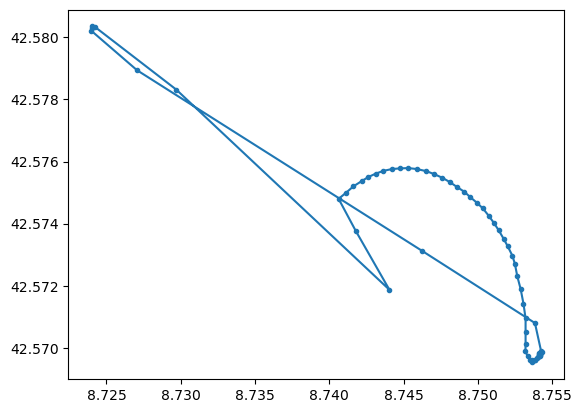

Python: [<matplotlib.lines.Line2D object at 0x7fd774ced110>]

In [206]:
plot(lon,lat,".-")

In [207]:
time_start = DateTime(2026,5,4,  11,44) # year, month, day, hour, minute

2026-05-04T11:44:00

In [208]:
time_end = DateTime(2026,5,4,  15,43) # year, month, day, hour, minute

2026-05-04T15:43:00

In [209]:
isel = findall(time_start .< time .< time_end)

48-element Vector{Int64}:
  5
  6
  7
  8
  9
 10
 11
 12
 13
 14
 15
 16
 17
  ⋮
 41
 42
 43
 44
 45
 46
 47
 48
 49
 50
 51
 52

In [210]:
lon = lon[isel]
lat = lat[isel]
time = time[isel]

48-element Vector{DateTime}:
 2026-05-04T11:47:00
 2026-05-04T11:52:00
 2026-05-04T11:57:00
 2026-05-04T12:02:00
 2026-05-04T12:07:00
 2026-05-04T12:12:00
 2026-05-04T12:17:00
 2026-05-04T12:22:00
 2026-05-04T12:27:00
 2026-05-04T12:32:00
 2026-05-04T12:37:00
 2026-05-04T12:42:00
 2026-05-04T12:47:00
 ⋮
 2026-05-04T14:47:00
 2026-05-04T14:52:00
 2026-05-04T14:57:00
 2026-05-04T15:02:00
 2026-05-04T15:07:00
 2026-05-04T15:12:00
 2026-05-04T15:17:00
 2026-05-04T15:21:00
 2026-05-04T15:26:00
 2026-05-04T15:31:00
 2026-05-04T15:36:00
 2026-05-04T15:42:00

In [211]:
DeltaT = Dates.value(time[2] - time[1]) / 1000

300.0

In [212]:
a = 111000 # m

111000

In [213]:
# cosd like cos but for degrees instead of radians

In [214]:
DeltaY = (lat[2] - lat[1]) * a
mean_lat = (lat[2] + lat[1])/2
DeltaX = (lon[2] - lon[1]) * a * cosd(mean_lat)

41.687238339397325

In [215]:
u = DeltaX / DeltaT
v = DeltaY / DeltaT


0.07399999999982754

In [216]:
(u,v) # m/s

(0.13895746113132443, 0.07399999999982754)

In [217]:
n = length(time)

48

In [218]:
u = zeros(n-1);
v = zeros(n-1);
mlon = zeros(n-1);
mlat = zeros(n-1);

for i = 1:(n-1)
  DeltaT = Dates.value(time[i+1] - time[i]) / 1000
  DeltaY = (lat[i+1] - lat[i]) * a
  mlat[i] = (lat[i+1] + lat[i])/2
  mlon[i] = (lon[i+1] + lon[i])/2
  DeltaX = (lon[i+1] - lon[i]) * a * cosd(mlat[i])
  u[i] = DeltaX / DeltaT
  v[i] = DeltaY / DeltaT
end

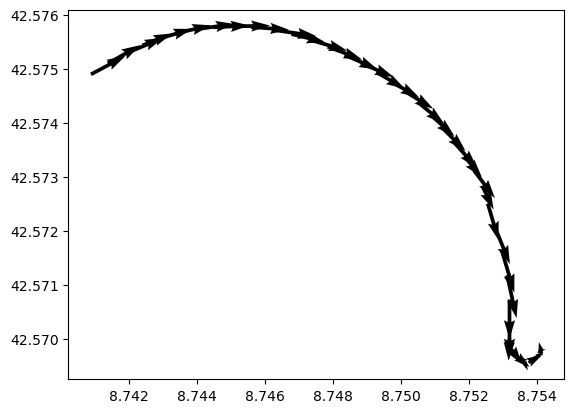

Python: <matplotlib.quiver.Quiver object at 0x7fd774de0b90>

In [219]:
quiver(mlon,mlat,u,v)

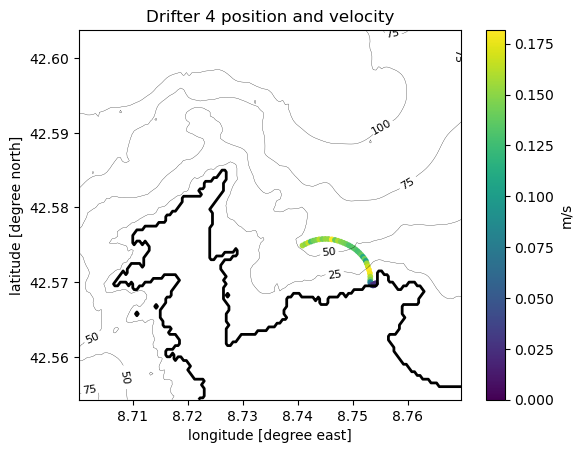

In [220]:
contour(bat_lon,bat_lat,isnan.(bat)',levels = [0.5],colors="k",linewidths=2); 
CS = contour(bat_lon,bat_lat,-bat',levels = [25, 50, 75, 100],colors="k",linewidths=0.2); 
gca().clabel(CS, CS.levels, inline=true, fontsize=8)
speed = sqrt.(u.^2 + v.^2);
scatter(mlon,mlat,10,speed); 
colorbar(label="m/s")
xlabel("longitude [degree east]")
ylabel("latitude [degree north]")
title("Drifter 4 position and velocity")
gca().set_aspect(1/cosd(mean(bat_lat)));

In [221]:
filename_temperature = "430000004B68CC41_050426_drifter04.csv"

"430000004B68CC41_050426_drifter04.csv"

In [222]:
data,h = readdlm(filename_temperature,',',skipstart=19,header=true)
h

1×4 Matrix{AbstractString}:
 "Date/Time"  "Unit"  "Value"  ""

In [223]:
data[1,1]

"4/05/26 10:44:01"

In [224]:
temp_time = DateTime.(data[:,1],"d/m/y HH:MM:SS") .+ Dates.Year(2000);

In [225]:
temp_time[1]

2026-05-04T10:44:01

In [226]:
data[1,2]

"C"

In [227]:
@assert(all(data[:,2] .== "C"))

In [228]:
data[1,3]

28

In [229]:
data[1,4]

677

In [230]:
string(data[1,3],'.',data[1,4])

"28.677"

In [231]:
temp = parse.(Float64,string.(data[:,3],'.',data[:,4]));

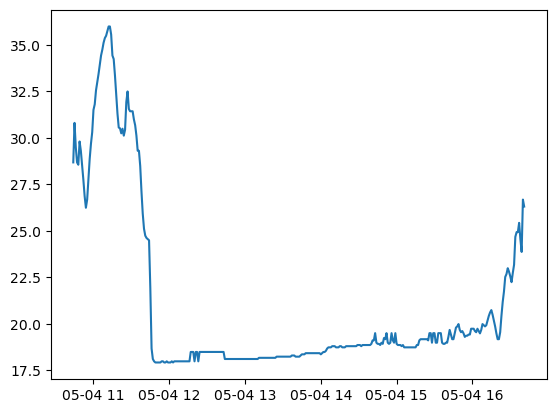

Python: [<matplotlib.lines.Line2D object at 0x7fd774a96810>]

In [232]:
plot(temp_time,temp)

In [233]:
using Interpolations

In [234]:
Dates.datetime2julian.(time)

48-element Vector{Float64}:
 2.4611649909722223e6
 2.4611649944444443e6
 2.461164997916667e6
 2.461165001388889e6
 2.4611650048611113e6
 2.4611650083333333e6
 2.461165011805556e6
 2.461165015277778e6
 2.46116501875e6
 2.4611650222222223e6
 2.4611650256944443e6
 2.461165029166667e6
 2.461165032638889e6
 ⋮
 2.4611651159722223e6
 2.4611651194444443e6
 2.461165122916667e6
 2.461165126388889e6
 2.4611651298611113e6
 2.4611651333333333e6
 2.461165136805556e6
 2.4611651395833334e6
 2.4611651430555554e6
 2.461165146527778e6
 2.46116515e6
 2.461165154166667e6

In [235]:
itp = interpolate((Dates.datetime2julian.(temp_time),),temp,Gridded(Linear()));

In [236]:
temp_drifter_positions = itp.(Dates.datetime2julian.(time));

In [237]:
temp_drifter_positions

48-element Vector{Float64}:
 18.12038328299721
 17.924
 17.924
 17.9849666722099
 17.986
 17.986
 18.481600045061114
 18.49
 18.49
 18.49
 18.49
 18.49
 18.111
  ⋮
 18.86304999436736
 19.4945833623906
 19.11846663197676
 18.862
 18.737
 18.737
 18.862
 19.175
 19.49353336802324
 18.99554995413422
 18.99554995413422
 19.668750033527612

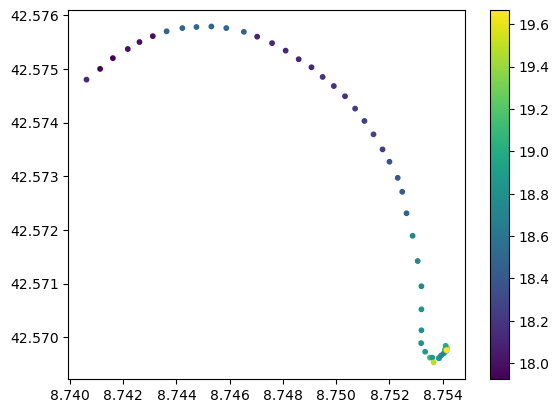

Python: <matplotlib.colorbar.Colorbar object at 0x7fd774b0db50>

In [238]:
scatter(lon,lat,10,temp_drifter_positions); colorbar()

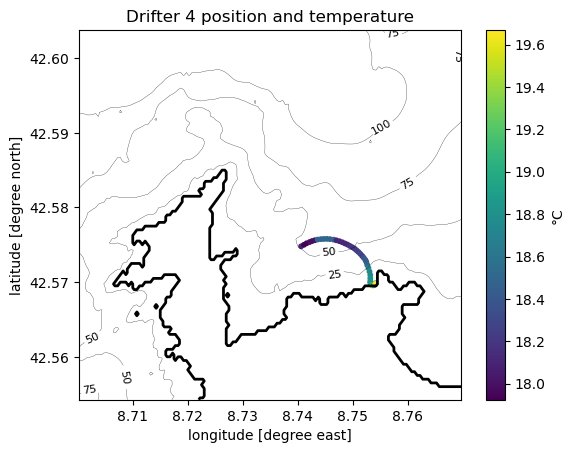

In [239]:
contour(bat_lon,bat_lat,isnan.(bat)',levels = [0.5],colors="k",linewidths=2); 
CS = contour(bat_lon,bat_lat,-bat',levels = [25, 50, 75, 100],colors="k",linewidths=0.2); 
gca().clabel(CS, CS.levels, inline=true, fontsize=8)
speed = sqrt.(u.^2 + v.^2);
scatter(lon,lat,10,temp_drifter_positions)
colorbar(label="°C")
xlabel("longitude [degree east]")
ylabel("latitude [degree north]")
title("Drifter 4 position and temperature")
gca().set_aspect(1/cosd(mean(bat_lat)));

In [240]:
function load_gnss_spot(filename,time_start,time_end)
   data, h = readdlm(filename,',',skipstart=5,header=true)
   @assert h[2] == "Date"
   @assert h[4] == "Lat/Lng"
   time = DateTime.(data[:,2],"d/m/y HH:MM")
   sel = findall(data[:,4] .!= "");
   time = time[sel]
   latlon = parse.(Float64,reduce(hcat,split.(data[sel,4],',')))
   lat = latlon[1,:];
   lon = latlon[2,:];
   isel = findall(time_start .< time .< time_end)
   lon = lon[isel]
   lat = lat[isel]
   time = time[isel]
   return lon,lat,time
end

function compute_currents(lon,lat,time)
    a = 111000 # m, earth_radius*pi/180
    
    n = length(time)
    u = zeros(n-1);
    v = zeros(n-1);
    mlon = zeros(n-1);
    mlat = zeros(n-1);

    for i = 1:(n-1)
        DeltaT = Dates.value(time[i+1] - time[i]) / 1000
        DeltaY = (lat[i+1] - lat[i]) * a
        mlat[i] = (lat[i+1] + lat[i])/2
        mlon[i] = (lon[i+1] + lon[i])/2
        DeltaX = (lon[i+1] - lon[i]) * a * cosd(mlat[i])
        u[i] = DeltaX / DeltaT
        v[i] = DeltaY / DeltaT
    end
    return mlon,mlat,u,v
end

function load_temperature(filename_temperature)
    @show filename_temperature
    data,h = readdlm(filename_temperature,',',skipstart=19,header=true)
    @assert h[1] == "Date/Time"
    @assert h[2] == "Unit"
    @assert h[3] == "Value"
    temp_time = DateTime.(data[:,1],"d/m/y HH:MM:SS") .+ Dates.Year(2000);
    @assert(all(data[:,2] .== "C"))
    temp = parse.(Float64,string.(data[:,3],'.',data[:,4])); 
    return (temp_time,temp)
end


function plot_currents(filename,time_start,time_end)
    (lon,lat,time) = load_gnss_spot(filename,time_start,time_end)
    (mlon,mlat,u,v) = compute_currents(lon,lat,time);
    speed = sqrt.(u.^2 + v.^2);
    scatter(mlon,mlat,10,speed,vmin=0,vmax=0.25);
end

function plot_temperature(filename,filename_temperature,time_start,time_end)
    (lon,lat,time) = load_gnss_spot(filename,time_start,time_end)
    (temp_time,temp) = load_temperature(filename_temperature)
    itp = interpolate((Dates.datetime2julian.(temp_time),),temp,Gridded(Linear()));
    temp_drifter_positions = itp.(Dates.datetime2julian.(time));
    scatter(lon,lat,10,temp_drifter_positions,vmin=18,vmax=20)
end


function plot_map(bat_lon,bat_lat,bat)
    contour(bat_lon,bat_lat,isnan.(bat)',levels = [0.5],colors="k",linewidths=2); 
    CS = contour(bat_lon,bat_lat,-bat',levels = [25, 50, 75, 100],colors="k",linewidths=0.2); 
    gca().clabel(CS, CS.levels, inline=true, fontsize=8)
    xlabel("longitude [degree east]")
    ylabel("latitude [degree north]")
    gca().set_aspect(1/cosd(mean(bat_lat)));
end

plot_map (generic function with 1 method)

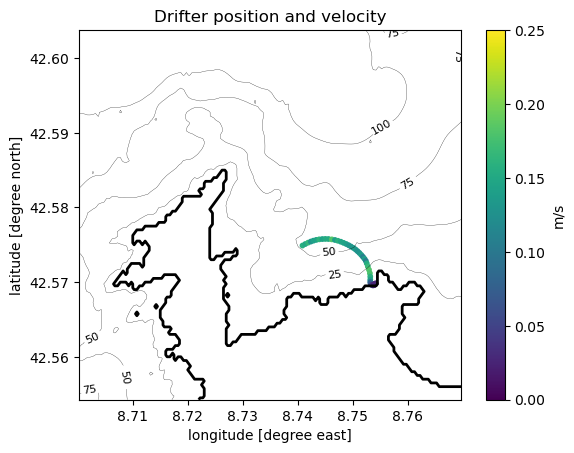

In [241]:
plot_map(bat_lon,bat_lat,bat)
plot_currents(filename,time_start,time_end)
# add here other files
colorbar(label="m/s")
title("Drifter position and velocity");

filename_temperature = "430000004B68CC41_050426_drifter04.csv"


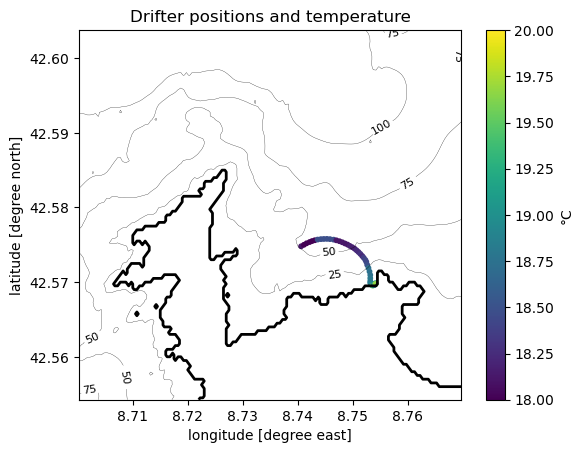

In [242]:
plot_map(bat_lon,bat_lat,bat)
plot_temperature(filename,filename_temperature,time_start,time_end)
colorbar(label="°C")
title("Drifter positions and temperature");

One line per drifter

In [243]:
filenames = [
    "ActivityReport-3-drifter04.csv", # other here
    ]
filename_temperatures = [
    "430000004B68CC41_050426_drifter04.csv",
    ]
time_starts = [
    DateTime(2026,5,4,  11,44),
    ]
time_ends = [
    DateTime(2026,5,4,  15,43),
    ]

1-element Vector{DateTime}:
 2026-05-04T15:43:00

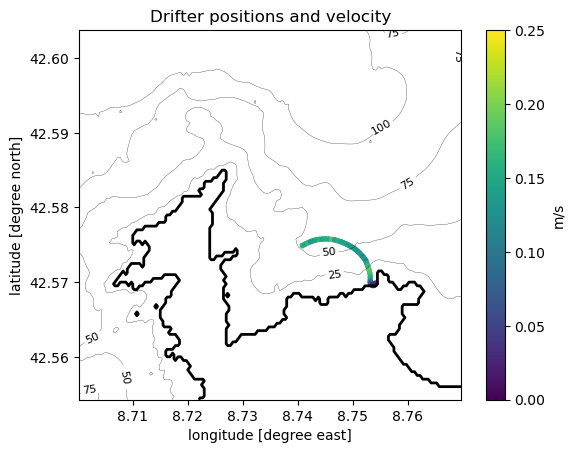

In [244]:
plot_map(bat_lon,bat_lat,bat)
plot_currents.(filenames,time_starts,time_ends)
colorbar(label="m/s")
title("Drifter positions and velocity");

filename_temperature = "430000004B68CC41_050426_drifter04.csv"


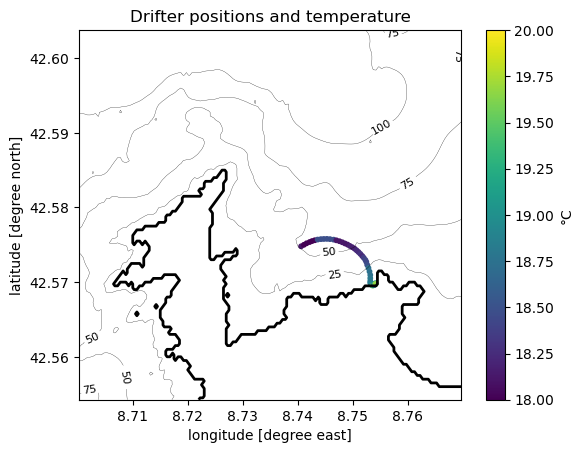

In [245]:
plot_map(bat_lon,bat_lat,bat)
plot_temperature.(filenames,filename_temperatures,time_starts,time_ends)
# to exlcude the last
plot_temperature.(filenames[1:end-1],filename_temperatures[1:end-1],time_starts[1:end-1],time_ends[1:end-1])

colorbar(label="°C")
title("Drifter positions and temperature");